In [ ]:
import yfinance as yf
import datetime as dt
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import numpy as np

In [ ]:
import warnings
warnings.filterwarnings("ignore")

In [ ]:
assets = [
  "AAPL", "MSFT", "NVDA",        # Technology
  "AMZN", "TSLA", "BKNG",        # Consumer Discretionary
  "AMGN", "GILD", "REGN",        # Health Care
  "COST", "MDLZ", "PEP",         # Consumer Staples
  "HON", "CSX", "CTAS",          # Industrials
  "EXC", "AEP", "XEL",           # Utilities
  "TMUS", "CMCSA", "CHTR" ,
  'UUP','GC=F','KC=F','ZW=F','ZS=F','SB=F','HG=F','USDJPY=X','VNQ','REET','IEF','BTC-USD','GBPUSD=X','FTSM'
]
start_check = "2013-1-1"
end_check = "2014-12-31"
data_check = yf.download(assets, start = start_check, end = end_check)['Close'].ffill().dropna()

start = "2015-1-1"
end = "2019-12-31"
data = yf.download(assets, start = start, end = end)['Close'].ffill().dropna()


[*********************100%***********************]  35 of 35 completed
[*********************100%***********************]  35 of 35 completed


In [ ]:
#check corr
check_return = data_check.pct_change().dropna()
corr_matrix = check_return.corr()
corr_matrix

Ticker,AAPL,AEP,AMGN,AMZN,BKNG,BTC-USD,CHTR,CMCSA,COST,CSX,...,REGN,SB=F,TMUS,TSLA,USDJPY=X,UUP,VNQ,XEL,ZS=F,ZW=F
Ticker,,,,,,,,,,,,,,,,,,,,,
AAPL,1.000000,0.133212,0.426612,0.424299,0.434963,0.093551,0.370775,0.482069,0.532123,0.396333,...,0.371310,0.022975,0.420647,0.543035,-0.011066,0.177365,0.435007,0.183314,0.098292,0.057638
AEP,0.133212,1.000000,0.320827,-0.034995,0.156607,-0.065021,0.146227,0.217370,0.313763,0.085720,...,0.246932,-0.038875,0.235331,-0.083739,0.080299,0.216705,0.460374,0.863579,-0.061026,0.015038
AMGN,0.426612,0.320827,1.000000,0.262758,0.357963,-0.095317,0.288081,0.409283,0.447247,0.220837,...,0.587668,-0.074183,0.445034,0.382364,-0.010564,0.228617,0.389956,0.344140,0.018637,0.068291
AMZN,0.424299,-0.034995,0.262758,1.000000,0.440460,-0.015142,0.201615,0.172199,0.376973,0.250067,...,0.153473,-0.105729,0.281365,0.449962,-0.154340,0.179152,0.324502,0.118773,0.102982,0.085612
BKNG,0.434963,0.156607,0.357963,0.440460,1.000000,-0.044095,0.350735,0.420350,0.192829,0.369434,...,0.492059,0.075629,0.504664,0.552714,-0.020159,0.136864,0.391297,0.201709,0.291581,0.108760
BTC-USD,0.093551,-0.065021,-0.095317,-0.015142,-0.044095,1.000000,-0.018927,-0.015957,0.032158,-0.018135,...,-0.012257,-0.009026,-0.099062,-0.016181,-0.014333,0.042456,-0.030967,-0.004393,-0.029840,0.115877
CHTR,0.370775,0.146227,0.288081,0.201615,0.350735,-0.018927,1.000000,0.812059,0.361648,0.172527,...,0.313382,-0.113985,0.353905,0.270643,0.170313,0.183444,0.312964,0.069178,0.019516,0.010307
CMCSA,0.482069,0.217370,0.409283,0.172199,0.420350,-0.015957,0.812059,1.000000,0.426171,0.288349,...,0.379363,-0.127280,0.443209,0.378871,0.103316,0.191750,0.325062,0.196651,0.112356,0.070532
COST,0.532123,0.313763,0.447247,0.376973,0.192829,0.032158,0.361648,0.426171,1.000000,0.126821,...,0.225985,-0.137517,0.320993,0.247426,0.010841,0.339273,0.458048,0.320597,-0.135669,0.026367


In [ ]:
def momentum_trade(ticker):
  df = pd.DataFrame()
  df['rets']= data[ticker].pct_change()
  df['rets_2'] = data[ticker].pct_change(periods = 2)
  # df['MA_rets'] = df['rets_2'].rolling(window = 10).mean()

  # df['pos']= np.where(df['rets_2'].shift(1) > df['MA_rets'], 1,  0)
  # df['strats_return'] = df['rets'] * df['pos']
  # sharpe = df['strats_return'].mean() / df['strats_return'].std()
  # cumm_ret = (df['strats_return'] + 1).cumprod()
  # print (f'Sharpe Ratio {ticker}: {sharpe} Cummulative Return: {cumm_ret[-1]}')
  # plt.plot(df['strats_return'].cumsum())
  return df['rets_2']


In [ ]:
# long_period = 89
# short_period = 34
# def MA_trade(ticker):
#   df = pd.DataFrame()
#   df['Close'] = data[ticker]
#   df['MA_long'] = df['Close'].rolling(window=long_period).mean()
#   df['MA_short'] = df['Close'].rolling(window=short_period).mean()
#   df['signal'] = np.where(df['MA_short'] > df['MA_long'], 1, np.where(df['MA_short'] < df['MA_long'], -1, 0))
#   df['return'] = data[ticker].pct_change()
#   df['strategy'] = df['signal'].shift(1) * df['return']
#   df.dropna(inplace=True)
#   df['cumret'] = (1 + df['strategy']).cumprod()

#   return df['strategy']

In [ ]:
def momentum_check(ticker):
  df = pd.DataFrame()
  df['momentum']= data[ticker].pct_change(period = 2)
  return df['momentum']


In [ ]:
momentum = pd.DataFrame()
for asset in assets:
  momentum[asset] = momentum_trade(asset)
momentum_min = momentum.min(axis = 1)
momentum_max = momentum.max(axis = 1)
min_max = momentum_max - momentum_min
weight = -2*momentum.sub(momentum_min, axis = 0).div(min_max, axis = 0) +1
weight



,AAPL,MSFT,NVDA,AMZN,TSLA,BKNG,AMGN,GILD,REGN,COST,...,ZS=F,SB=F,HG=F,USDJPY=X,VNQ,REET,IEF,BTC-USD,GBPUSD=X,FTSM
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-04,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,1.000000,-1.000000,-1.000000
2015-01-05,0.676767,0.234528,0.413851,0.498376,1.000000,0.927901,0.297162,-0.441436,-0.111047,0.285179,...,-0.845760,-0.127816,0.393788,-0.089446,-0.107342,-0.082423,-0.122001,0.568104,0.461214,0.027988
2015-01-06,0.502732,0.445538,0.747964,0.697716,0.615159,0.849117,0.708725,-0.247456,0.559020,0.110511,...,-0.504451,-0.517902,0.292944,0.181739,-0.070634,-0.010925,-0.036575,-0.963788,0.404582,0.139423
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-12-26,-0.188533,0.195144,0.386521,-1.000000,0.024336,0.137658,0.523705,0.628223,0.609648,0.297256,...,0.421258,0.292720,0.163411,0.469157,0.320946,0.283253,0.417466,0.841286,0.392567,0.457551
2019-12-27,-0.095527,0.237228,0.851291,-1.000000,0.165674,0.098543,0.708753,1.000000,0.891545,0.606492,...,0.856272,0.142643,0.616978,0.540693,0.325091,0.357824,0.489585,0.519522,0.408242,0.572040
2019-12-28,0.628820,0.541625,0.997022,0.592044,0.665160,0.456508,0.674248,0.875658,0.776121,0.830240,...,0.961393,0.319863,1.000000,0.551327,0.488956,0.570427,0.556628,0.182539,0.526494,0.600651


In [ ]:
ret = data.pct_change()
ret

Ticker,AAPL,AEP,AMGN,AMZN,BKNG,BTC-USD,CHTR,CMCSA,COST,CSX,...,REGN,SB=F,TMUS,TSLA,USDJPY=X,UUP,VNQ,XEL,ZS=F,ZW=F
Date,,,,,,,,,,,,,,,,,,,,,
2015-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2015-01-03,0.000000,0.000000,0.000000,0.000000,0.000000,-0.107767,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2015-01-04,0.000000,0.000000,0.000000,0.000000,0.000000,-0.060079,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2015-01-05,-0.028172,-0.014718,-0.011884,-0.020517,-0.038947,0.038907,-0.035631,-0.020394,-0.011369,-0.027057,...,0.005632,0.006351,-0.013553,-0.042041,0.004705,0.002066,0.005473,-0.011351,0.037157,0.013333
2015-01-06,0.000094,0.005477,-0.032217,-0.022833,-0.016053,0.042682,-0.026106,-0.013045,0.013214,-0.039851,...,-0.037772,0.042777,-0.002228,0.005664,-0.008378,0.002062,0.009919,0.005321,0.010820,0.004669
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-12-26,0.019840,0.000426,-0.001774,0.044467,0.009941,-0.004974,0.010128,0.009881,0.005098,-0.001507,...,-0.004382,0.005236,0.001035,0.013380,-0.000128,-0.001523,0.004379,-0.001114,0.001335,0.014787
2019-12-27,-0.000380,0.003302,-0.001530,0.000551,0.003982,0.007062,-0.004200,0.002891,-0.005478,-0.000274,...,-0.004108,0.007441,-0.002067,-0.001300,0.001582,-0.004958,0.003160,0.005256,-0.008798,0.013206
2019-12-28,0.000000,0.000000,0.000000,0.000000,0.000000,0.003827,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


Sharpe 0.008610811938741934
0.0001574816016182321


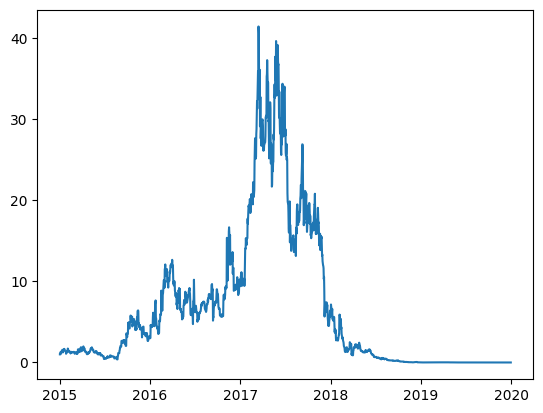

In [ ]:
pot_ret = (ret.mul(weight.shift(1))).sum(axis = 1)
# print(pot_ret)
sharpe = pot_ret.mean()/pot_ret.std()
print(f'Sharpe {sharpe}')
cumm_ret = (pot_ret + 1).cumprod()
print(cumm_ret[-1])
plt.plot(cumm_ret)


